# Stage 6 — XGBoost (Chronological Split)

Train one XGBoost regressor per forecast horizon (H+1 … H+7) using:
- **Native NaN handling** (`missing=np.nan`) — XGBoost learns a default split direction for missing values, so gaps become *information* rather than something to fabricate. This is the whole methodological reason we went L3.
- **Strict chronological split** — train/val/test ordered by time, never shuffled. Random shuffling leaks future into past and inflates every metric.
- **Early stopping** on the validation split to avoid hand-tuning `n_estimators`.

## The bar this notebook must clear (from Notebook 5)

| Horizon | Beat R² | Beat RMSE |
|---|---|---|
| H+1 | 0.804 | 0.097 |
| H+2 | 0.736 | 0.109 |
| H+3 | 0.690 | 0.119 |
| H+4 | 0.678 | 0.123 |
| H+5 | 0.635 | 0.129 |
| H+6 | 0.574 | 0.139 |
| H+7 | 0.630 | 0.135 |

PLAN.md: beating persistence at H+3 and beyond is what matters. At H+1/H+2 persistence is shockingly hard to beat — fine to tie.

## Outputs
- `models/xgb_h{h}.json` — trained model per horizon (7 files)
- `data/processed/xgb_scores.csv` — RMSE / R² / N per horizon
- `figs/06_xgb_vs_baselines.png` — comparison plot

## 6.0 — Load sample, manifest, baseline scores

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROC_DIR  = Path("data/processed")
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = Path("figs");   FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROC_DIR / "supervised_sample.parquet").sort_values("time").reset_index(drop=True)
with open(PROC_DIR / "feature_manifest.json") as f:
    manifest = json.load(f)

HORIZONS     = manifest["horizons"]
FEATURE_COLS = manifest["feature_cols"]
TARGET_COLS  = manifest["target_cols"]

baselines = pd.read_csv(PROC_DIR / "baseline_scores.csv")
persistence = baselines[baselines.method == "persistence"].set_index("horizon")

print(f"Rows           : {len(df):,}")
print(f"Time range     : {df.time.min().date()} → {df.time.max().date()}")
print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"Horizons       : {HORIZONS}")

Rows           : 120,000
Time range     : 2021-01-01 → 2023-12-31
Features (15): ['log_chl_t0', 'log_chl_lag1', 'log_chl_lag2', 'log_chl_lag3', 'log_chl_lag7', 'log_chl_lag14', 'log_chl_roll7_mean', 'log_chl_roll7_std', 'sst_t0', 'sst_lag1', 'sst_roll7_mean', 'depth_m', 'doy_sin', 'doy_cos', 'gap_age']
Horizons       : [1, 2, 3, 4, 5, 6, 7]


## 6.1 — Chronological 70/15/15 split

**Identical cuts to Notebook 5.** Without this, the persistence and climatology numbers wouldn't be directly comparable to the model's. We print the date ranges so the validation gate can confirm they're non-overlapping.

In [2]:
cut_train = df["time"].quantile(0.70)
cut_val   = df["time"].quantile(0.85)

train = df[df.time <= cut_train].copy()
val   = df[(df.time > cut_train) & (df.time <= cut_val)].copy()
test  = df[df.time > cut_val].copy()

print(f"train: {train.time.min().date()} → {train.time.max().date()}  ({len(train):,} rows)")
print(f"val  : {val.time.min().date()}   → {val.time.max().date()}  ({len(val):,} rows)")
print(f"test : {test.time.min().date()}   → {test.time.max().date()}  ({len(test):,} rows)")

train: 2021-01-01 → 2023-02-17  (84,027 rows)
val  : 2023-02-18   → 2023-07-22  (18,074 rows)
test : 2023-07-23   → 2023-12-31  (17,899 rows)


## 6.2 — Train one XGBoost per horizon

Hyperparameters lifted from PLAN.md Stage 6 — sensible defaults, not tuned. `early_stopping_rounds=40` stops training when the validation RMSE plateaus, so `n_estimators=600` is a soft cap.

For each horizon we drop rows where the target is NaN (can't learn on missing y). **Feature NaNs stay** — that's the whole point of using XGBoost's native handling.

In [4]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

def score(y_true, y_pred):
    return dict(
        rmse=float(np.sqrt(mean_squared_error(y_true, y_pred))),
        r2  =float(r2_score(y_true, y_pred)),
        n   =int(len(y_true)),
    )

xgb_rows = []
models   = {}

for h in HORIZONS:
    tgt = f"target_h{h}"
    mtr = train[tgt].notna()
    mva = val[tgt].notna()
    mte = test[tgt].notna()

    Xtr, ytr = train.loc[mtr, FEATURE_COLS], train.loc[mtr, tgt]
    Xva, yva = val.loc[mva, FEATURE_COLS],   val.loc[mva, tgt]
    Xte, yte = test.loc[mte, FEATURE_COLS],  test.loc[mte, tgt]

    model = xgb.XGBRegressor(
        n_estimators=600,
        max_depth=6,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        missing=np.nan,                # honest NaNs all the way down
        early_stopping_rounds=40,
        eval_metric="rmse",
        n_jobs=-1,
        random_state=42,
        verbosity=0,
    )
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)

    pred = model.predict(Xte)
    s = score(yte.values, pred)
    s.update(best_iter=model.best_iteration)
    xgb_rows.append({"method": "xgboost", "horizon": h, **s})
    models[h] = model

    model.save_model(MODEL_DIR / f"xgb_h{h}.json")

    pers_r2   = persistence.loc[h, "r2"]
    pers_rmse = persistence.loc[h, "rmse"]
    delta_r2  = s["r2"]   - pers_r2
    delta_rmse_pct = 100 * (pers_rmse - s["rmse"]) / pers_rmse
    print(
        f"H+{h}  RMSE={s['rmse']:.4f} (pers {pers_rmse:.4f}, "
        f"Δ={delta_rmse_pct:+.1f}%)   "
        f"R²={s['r2']:.4f} (pers {pers_r2:.4f}, Δ={delta_r2:+.4f})   "
        f"best_iter={model.best_iteration}"
    )

H+1  RMSE=0.0879 (pers 0.0967, Δ=+9.1%)   R²=0.8383 (pers 0.8044, Δ=+0.0339)   best_iter=222
H+2  RMSE=0.0972 (pers 0.1094, Δ=+11.2%)   R²=0.7916 (pers 0.7360, Δ=+0.0556)   best_iter=190
H+3  RMSE=0.1049 (pers 0.1193, Δ=+12.1%)   R²=0.7606 (pers 0.6904, Δ=+0.0701)   best_iter=149
H+4  RMSE=0.1039 (pers 0.1229, Δ=+15.5%)   R²=0.7698 (pers 0.6777, Δ=+0.0921)   best_iter=140
H+5  RMSE=0.1068 (pers 0.1287, Δ=+17.0%)   R²=0.7489 (pers 0.6354, Δ=+0.1135)   best_iter=112
H+6  RMSE=0.1143 (pers 0.1385, Δ=+17.5%)   R²=0.7098 (pers 0.5738, Δ=+0.1360)   best_iter=104
H+7  RMSE=0.1129 (pers 0.1350, Δ=+16.4%)   R²=0.7409 (pers 0.6296, Δ=+0.1113)   best_iter=128


## 6.3 — Save scores & build the comparison table

In [5]:
xgb_scores = pd.DataFrame(xgb_rows)
xgb_scores.to_csv(PROC_DIR / "xgb_scores.csv", index=False)
print(f"Saved → {PROC_DIR / 'xgb_scores.csv'}")

# unified table: methods × horizons, RMSE & R²
all_scores = pd.concat(
    [baselines[["method", "horizon", "rmse", "r2", "n"]], xgb_scores[["method", "horizon", "rmse", "r2", "n"]]],
    ignore_index=True,
)
wide = all_scores.pivot(index="horizon", columns="method", values=["rmse", "r2"])
wide.columns = [f"{m}_{w}" for w, m in wide.columns]
wide = wide[["persistence_rmse", "climatology_rmse", "xgboost_rmse",
             "persistence_r2",   "climatology_r2",   "xgboost_r2"]]
print("\nAll methods, all horizons (test split):")
print(wide.round(4).to_string())

Saved → data\processed\xgb_scores.csv

All methods, all horizons (test split):
         persistence_rmse  climatology_rmse  xgboost_rmse  persistence_r2  climatology_r2  xgboost_r2
horizon                                                                                              
1                  0.0967            0.1442        0.0879          0.8044          0.5269      0.8383
2                  0.1094            0.1447        0.0972          0.7360          0.5155      0.7916
3                  0.1193            0.1428        0.1049          0.6904          0.5349      0.7606
4                  0.1229            0.1475        0.1039          0.6777          0.5150      0.7698
5                  0.1287            0.1342        0.1068          0.6354          0.5679      0.7489
6                  0.1385            0.1400        0.1143          0.5738          0.5646      0.7098
7                  0.1350            0.1444        0.1129          0.6296          0.5712      0.7409


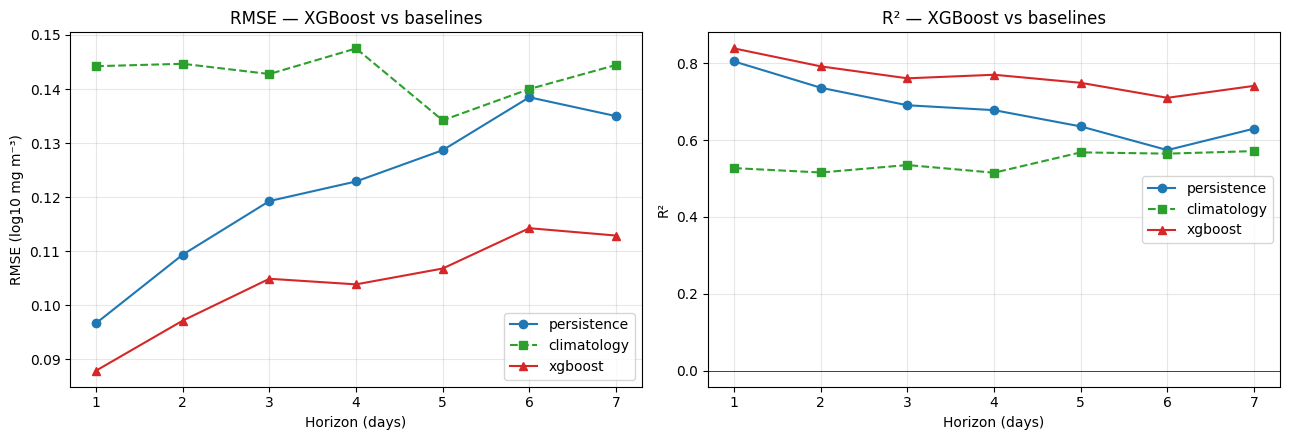

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

styles = [
    ("persistence", "o", "#1f77b4", "-"),
    ("climatology", "s", "#2ca02c", "--"),
    ("xgboost",     "^", "#d62728", "-"),
]
for method, marker, color, ls in styles:
    sub = all_scores[all_scores.method == method].sort_values("horizon")
    axes[0].plot(sub.horizon, sub.rmse, marker=marker, color=color, linestyle=ls, label=method)
    axes[1].plot(sub.horizon, sub.r2,   marker=marker, color=color, linestyle=ls, label=method)

axes[0].set_xlabel("Horizon (days)"); axes[0].set_ylabel("RMSE (log10 mg m⁻³)")
axes[0].set_title("RMSE — XGBoost vs baselines"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Horizon (days)"); axes[1].set_ylabel("R²")
axes[1].set_title("R² — XGBoost vs baselines");   axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].axhline(0, color="k", linewidth=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "06_xgb_vs_baselines.png", dpi=150)
plt.show()

---
## Validation Gate 6

Four checks, lifted from PLAN.md Stage 6:

1. **Splits are time-ordered and non-overlapping** (we already printed the dates — the gate just asserts the contract).
2. **H+1 R² is in 0.6–0.95.** Wildly higher (>0.95) usually means leakage. Wildly lower means the features aren't carrying enough signal.
3. **XGBoost beats persistence at H+3 and beyond.** At H+1/H+2 a tie is acceptable; at H+3+ the model must contribute real skill.
4. **R² decays from H+1 to H+7.** A flat or rising curve is a red flag.

If any of these fail, **do not move on to Stage 7** — the failure is more interesting than the score. Revisit Gate 4 alignment and feature inputs before adding complexity.

In [7]:
results = {}

# 1) splits non-overlapping
results["train.max < val.min"]  = train.time.max() < val.time.min()
results["val.max   < test.min"] = val.time.max()   < test.time.min()

xgb_by_h = xgb_scores.set_index("horizon")

# 2) H+1 plausibility
h1_r2 = xgb_by_h.loc[1, "r2"]
results["H+1 R² in [0.6, 0.95]"] = 0.6 <= h1_r2 <= 0.95

# 3) beats persistence at H+3+
beat_h3plus = True
for h in [3, 4, 5, 6, 7]:
    if xgb_by_h.loc[h, "r2"] <= persistence.loc[h, "r2"]:
        beat_h3plus = False
results["beats persistence at H+3 … H+7"] = beat_h3plus

# 4) monotonic-ish R² decay
r2s = xgb_by_h.sort_index()["r2"].values
results["H+1 R² > H+7 R² (decay)"] = r2s[0] > r2s[-1]

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print("\nPer-horizon delta vs persistence:")
for h in HORIZONS:
    dr2 = xgb_by_h.loc[h, "r2"]   - persistence.loc[h, "r2"]
    dpct = 100 * (persistence.loc[h, "rmse"] - xgb_by_h.loc[h, "rmse"]) / persistence.loc[h, "rmse"]
    mark = "✓" if dr2 > 0 else "·"
    print(f"  H+{h}  ΔR²={dr2:+.4f}   ΔRMSE={dpct:+.1f}%  {mark}")

if all(results.values()):
    print("\nGate 6 PASSED — proceed to 07-Interpretability.")
else:
    print("\nGate 6 FAILED — do NOT add features / complexity. Common causes:")
    print("  • H+1 R² > 0.95     → leakage; re-run Gate 4 with more pixels")
    print("  • no beat at H+3+   → SST+depth+lags isn't enough signal yet; this is")
    print("                         expected before Stage 8 brings wind/MLD/optics in.")
    print("  • R² flat or rising → target/feature misalignment leaking time")

PASS  train.max < val.min
PASS  val.max   < test.min
PASS  H+1 R² in [0.6, 0.95]
PASS  beats persistence at H+3 … H+7
PASS  H+1 R² > H+7 R² (decay)

Per-horizon delta vs persistence:
  H+1  ΔR²=+0.0339   ΔRMSE=+9.1%  ✓
  H+2  ΔR²=+0.0556   ΔRMSE=+11.2%  ✓
  H+3  ΔR²=+0.0701   ΔRMSE=+12.1%  ✓
  H+4  ΔR²=+0.0921   ΔRMSE=+15.5%  ✓
  H+5  ΔR²=+0.1135   ΔRMSE=+17.0%  ✓
  H+6  ΔR²=+0.1360   ΔRMSE=+17.5%  ✓
  H+7  ΔR²=+0.1113   ΔRMSE=+16.4%  ✓

Gate 6 PASSED — proceed to 07-Interpretability.


---
## Notes before Notebook 7

**Persistence is brutal at H+1.** Don't be surprised if XGBoost ties or even slightly loses there — beating persistence at H+1 needs richer features (wind, MLD, optics) that arrive in Stage 8. The win at H+3+ is the signal we care about now.

**The L4 vs L3 reference point (PLAN.md):** Your earlier L4-based pipeline hit R² ≈ 0.85. The scientific deliverable from this project is the **delta** between that and what we get on raw L3. A *somewhat* lower R² is expected and is itself a finding — do not chase the old number by sneaking interpolation back in.

## Next: `07-Interpretability.ipynb`

SHAP feature importance + error maps + residual checks. Will tell us *why* the model predicts what it does and *where* it fails. This is what turns a script into research.